In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Task 0

In [88]:
df = pd.read_csv('quickbite_customers.csv')

In [89]:
df.head()

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,NaN,21.6,4.0,Basic,17,8675.0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,NaN,42.9,7.0,Basic,379,90202.0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0


In [90]:
df.describe()

,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
count,2000.000000,1861.000000,2000.000000,2000.00000,1920.000000,1892.000000,1742.000000,1896.000000,2000.000000,2000.00000,2000.000000
mean,1.600500,31.926384,29.507300,13.93200,34.991198,417.577696,4.290356,22.499947,18.599500,34.89650,12995.852000
std,0.772138,7.619334,9.981302,3.77856,19.486015,1133.673898,0.609572,9.483931,18.983606,49.27424,30336.382856
min,1.000000,0.000000,12.000000,2.00000,15.600000,57.000000,1.000000,0.000000,0.000000,5.00000,523.000000
25%,1.000000,27.000000,20.775000,11.00000,26.200000,215.000000,4.000000,16.200000,5.000000,17.00000,4085.750000
50%,1.000000,32.000000,29.500000,14.00000,32.250000,315.500000,4.400000,22.400000,12.000000,24.00000,7142.000000
75%,2.000000,37.000000,37.925000,16.00000,40.500000,458.250000,4.700000,28.500000,26.000000,32.00000,12781.250000
max,3.000000,150.000000,46.600000,29.00000,500.000000,32000.000000,5.000000,55.900000,125.000000,400.00000,855443.000000


In [91]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             2000 non-null   object 
 1   signup_date             2000 non-null   object 
 2   city                    2000 non-null   object 
 3   city_tier               2000 non-null   int64  
 4   gender                  1894 non-null   object 
 5   device_type             2000 non-null   object 
 6   acquisition_channel     2000 non-null   object 
 7   age                     1861 non-null   float64
 8   tenure_months           2000 non-null   float64
 9   app_sessions_per_month  2000 non-null   int64  
 10  delivery_time_min       1920 non-null   float64
 11  avg_order_value         1892 non-null   float64
 12  customer_rating         1742 non-null   float64
 13  discount_used_pct       1896 non-null   float64
 14  days_since_last_order   2000 non-null   

In [92]:
df.shape

(2000, 18)

In [93]:
df.isnull().sum()

,0
customer_id,0
signup_date,0
city,0
city_tier,0
gender,106
device_type,0
acquisition_channel,0
age,139
tenure_months,0
app_sessions_per_month,0


# Task 1 Missing value handling

In [94]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

print(missing)

                        Missing_Count  Missing_Percentage
customer_id                         0                0.00
signup_date                         0                0.00
city                                0                0.00
city_tier                           0                0.00
gender                            106                5.30
device_type                         0                0.00
acquisition_channel                 0                0.00
age                               139                6.95
tenure_months                       0                0.00
app_sessions_per_month              0                0.00
delivery_time_min                  80                4.00
avg_order_value                   108                5.40
customer_rating                   258               12.90
discount_used_pct                 104                5.20
days_since_last_order               0                0.00
membership                          0                0.00
orders_last_12

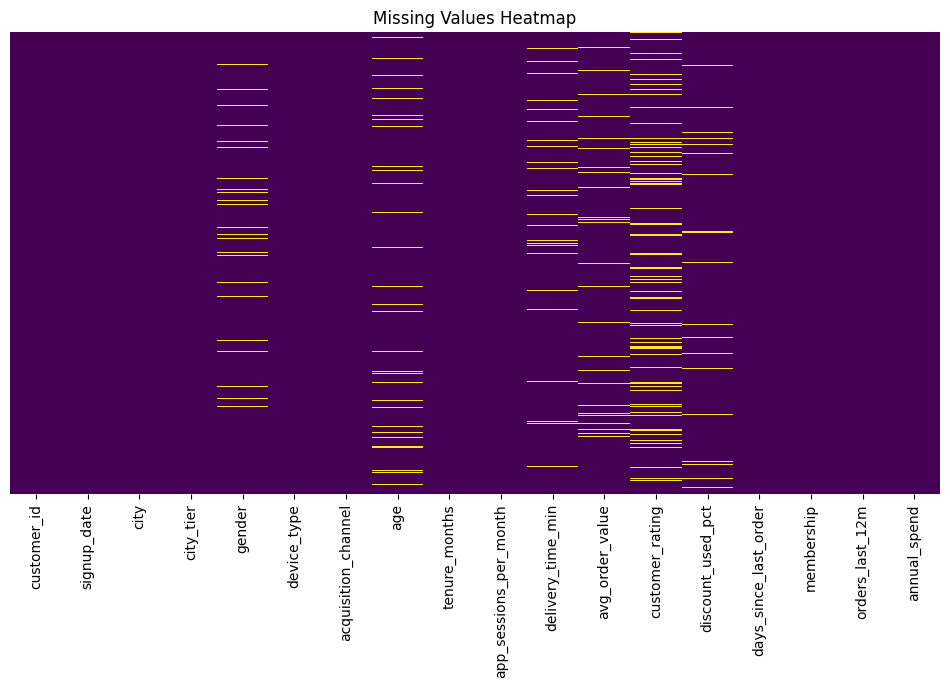

In [95]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'

)

plt.title("Missing Values Heatmap")
plt.show()

# Task 2 Outlier handling

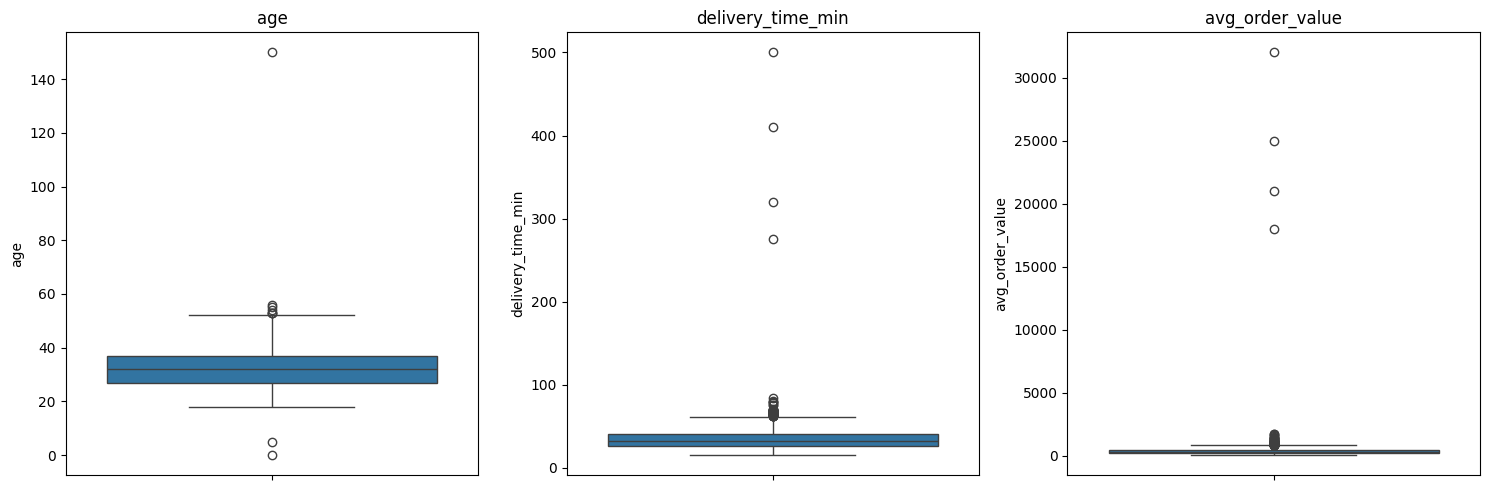

In [96]:
plt.figure(figsize=(15, 5))

columns = ['age', 'delivery_time_min',
           'avg_order_value']

for i, col in enumerate(columns):
    plt.subplot(1, 3, i+1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

# Task 3 Distribution Shapes with KDE Plots

In [97]:
data = df.copy()

In [98]:
columns = [
    'age',
    'customer_rating',
    'delivery_time_min',
    'avg_order_value',
    'annual_spend',
    'orders_last_12m'
]

Age Distribution

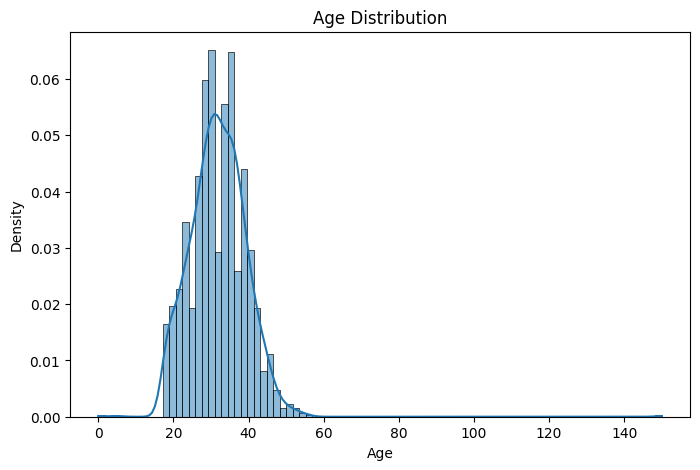

In [99]:
plt.figure(figsize=(8,5))

sns.histplot(
    data['age'].dropna(),
    kde=True,
    stat='density'
)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Density')

plt.show()

Customer Rating Distribution

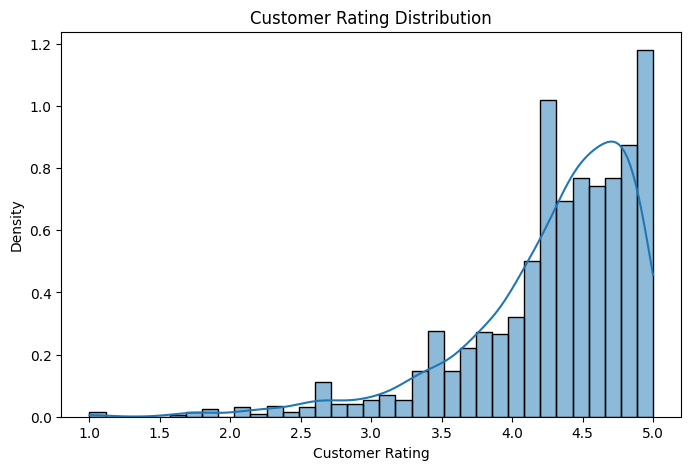

In [100]:
plt.figure(figsize=(8,5))

sns.histplot(
    data['customer_rating'].dropna(),
    kde=True,
    stat='density'
)

plt.title('Customer Rating Distribution')
plt.xlabel('Customer Rating')
plt.ylabel('Density')

plt.show()

Delivery Time Distribution

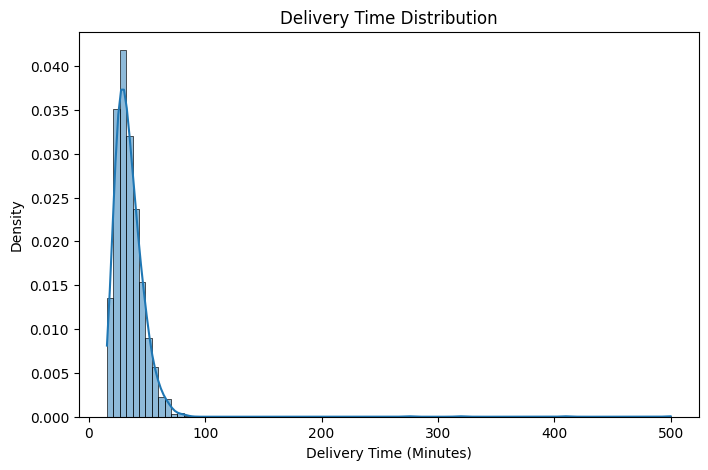

In [101]:
plt.figure(figsize=(8,5))

sns.histplot(
    data['delivery_time_min'].dropna(),
    kde=True,
    stat='density'
)

plt.title('Delivery Time Distribution')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Density')

plt.show()

Average Order Value Distribution

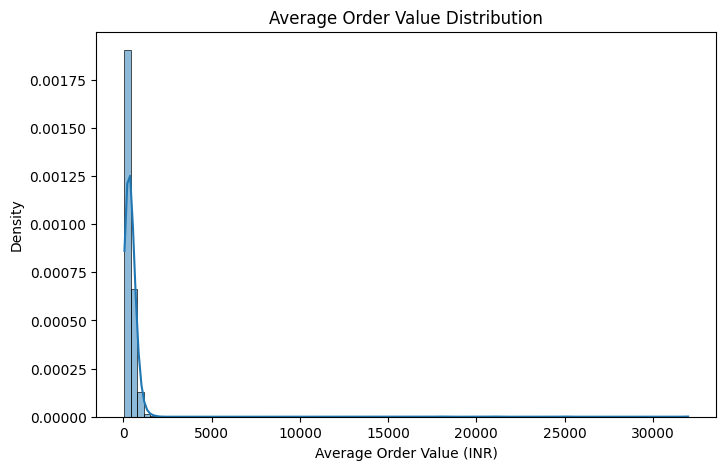

In [102]:
plt.figure(figsize=(8,5))

sns.histplot(
    data['avg_order_value'].dropna(),
    kde=True,
    stat='density'
)

plt.title('Average Order Value Distribution')
plt.xlabel('Average Order Value (INR)')
plt.ylabel('Density')

plt.show()

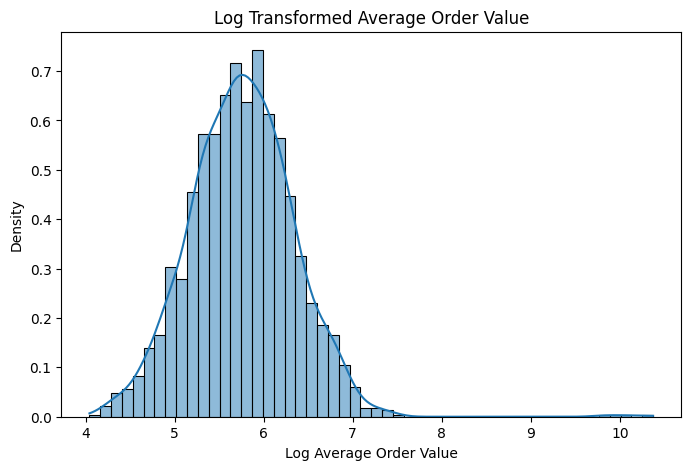

In [103]:
plt.figure(figsize=(8,5))

sns.histplot(
    np.log(data['avg_order_value'].dropna()),
    kde=True,
    stat='density'
)

plt.title('Log Transformed Average Order Value')
plt.xlabel('Log Average Order Value')
plt.ylabel('Density')

plt.show()

Annual Spend

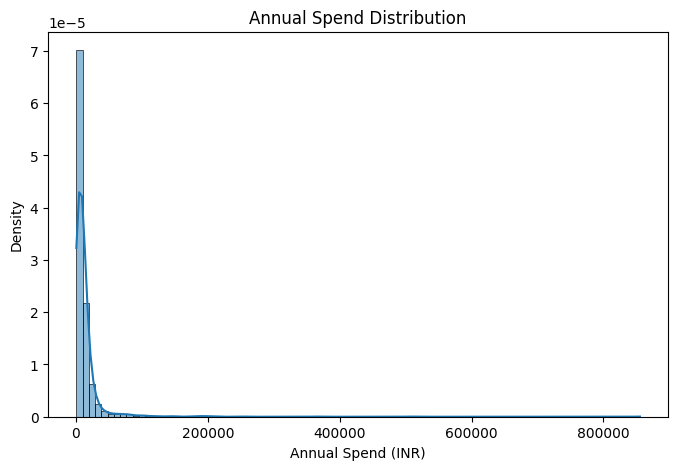

In [104]:
plt.figure(figsize=(8,5))

sns.histplot(
    data['annual_spend'].dropna(),
    kde=True,
    stat='density'
)

plt.title('Annual Spend Distribution')
plt.xlabel('Annual Spend (INR)')
plt.ylabel('Density')

plt.show()

Orders Last 12 Months

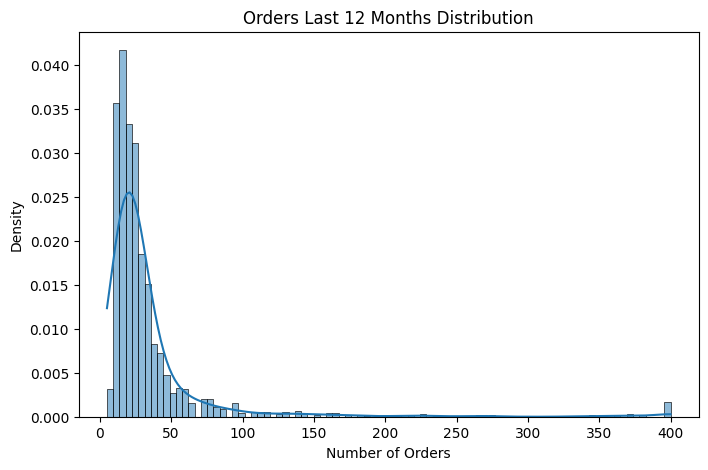

In [105]:
plt.figure(figsize=(8,5))

sns.histplot(
    data['orders_last_12m'].dropna(),
    kde=True,
    stat='density'
)

plt.title('Orders Last 12 Months Distribution')
plt.xlabel('Number of Orders')
plt.ylabel('Density')

plt.show()

Calculate skewness

In [106]:
print("Age Skewness:", data['age'].skew())

print("Customer Rating Skewness:",
      data['customer_rating'].skew())

print("Delivery Time Skewness:",
      data['delivery_time_min'].skew())

print("Average Order Value Skewness:",
      data['avg_order_value'].skew())

print("Annual Spend Skewness:",
      data['annual_spend'].skew())

print("Orders Last 12 Months Skewness:",
      data['orders_last_12m'].skew())

Age Skewness: 2.030268272526853
Customer Rating Skewness: -1.631757002178984
Delivery Time Skewness: 13.552453437640326
Average Order Value Skewness: 21.993512750673542
Annual Spend Skewness: 15.238484519499103
Orders Last 12 Months Skewness: 5.310773032270558


# Task 4 Relationships Between Variables

In [107]:
corr_matrix = data.corr(numeric_only=True)

print(corr_matrix)

                        city_tier       age  tenure_months  \
city_tier                1.000000  0.005004       0.015230   
age                      0.005004  1.000000       0.021688   
tenure_months            0.015230  0.021688       1.000000   
app_sessions_per_month   0.017946 -0.016884      -0.005137   
delivery_time_min        0.115724  0.056871       0.010804   
avg_order_value         -0.057385 -0.034075      -0.047264   
customer_rating         -0.009166 -0.018320       0.022057   
discount_used_pct       -0.022469 -0.240253      -0.001693   
days_since_last_order    0.025767 -0.016054      -0.015789   
orders_last_12m          0.024920  0.007749      -0.015602   
annual_spend            -0.004363  0.023505      -0.012000   

                        app_sessions_per_month  delivery_time_min  \
city_tier                             0.017946           0.115724   
age                                  -0.016884           0.056871   
tenure_months                        -0.005137  

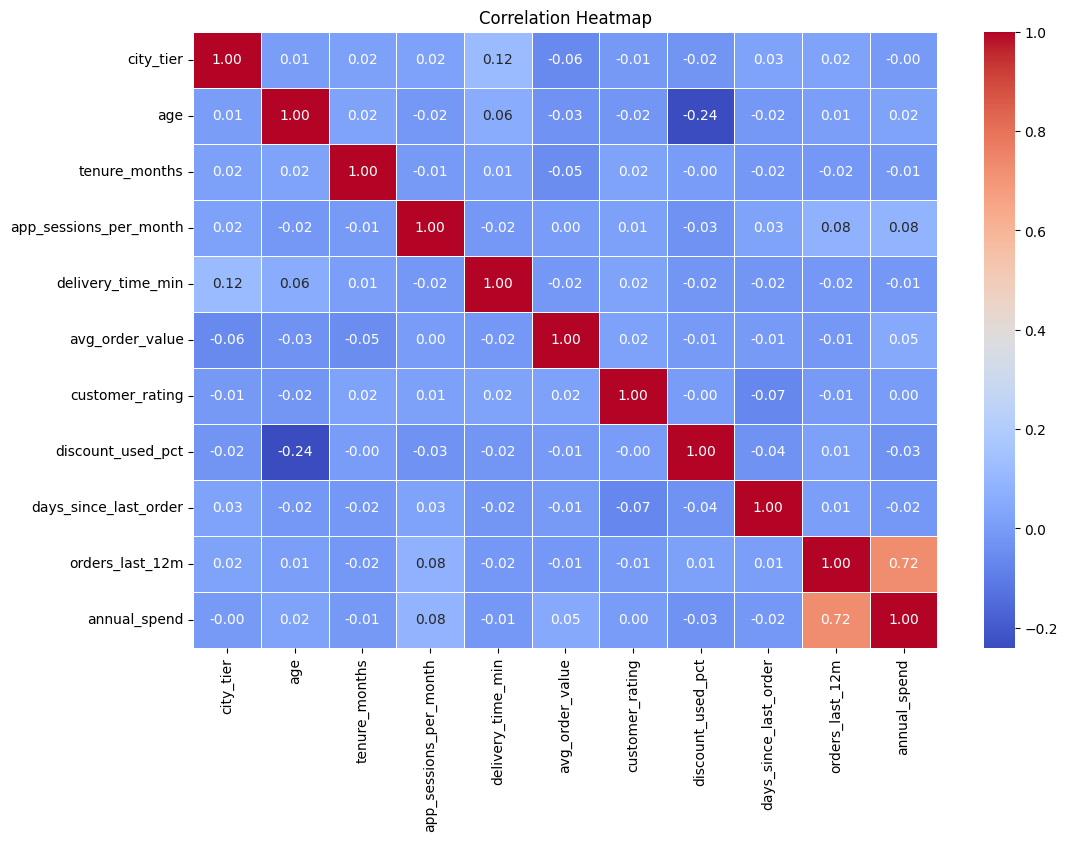

In [108]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')

plt.show()

Scatter Plot

Orders vs Annual Spend

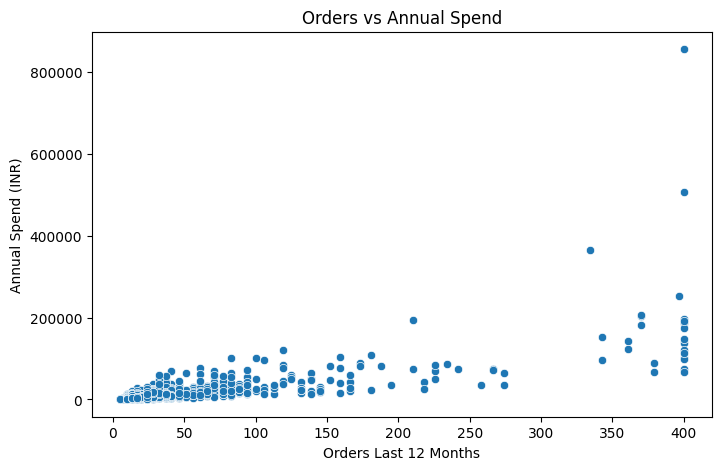

In [109]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x='orders_last_12m',
    y='annual_spend'
)

plt.title('Orders vs Annual Spend')
plt.xlabel('Orders Last 12 Months')
plt.ylabel('Annual Spend (INR)')

plt.show()

App Sessions vs Orders

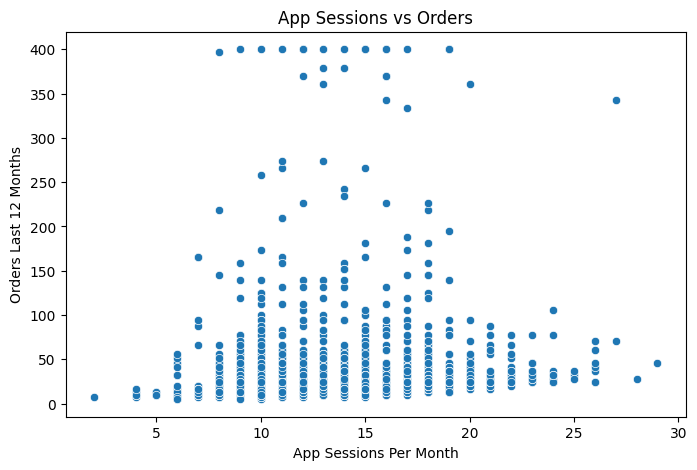

In [110]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x='app_sessions_per_month',
    y='orders_last_12m'
)

plt.title('App Sessions vs Orders')
plt.xlabel('App Sessions Per Month')
plt.ylabel('Orders Last 12 Months')

plt.show()

Delivery Time vs Customer Rating

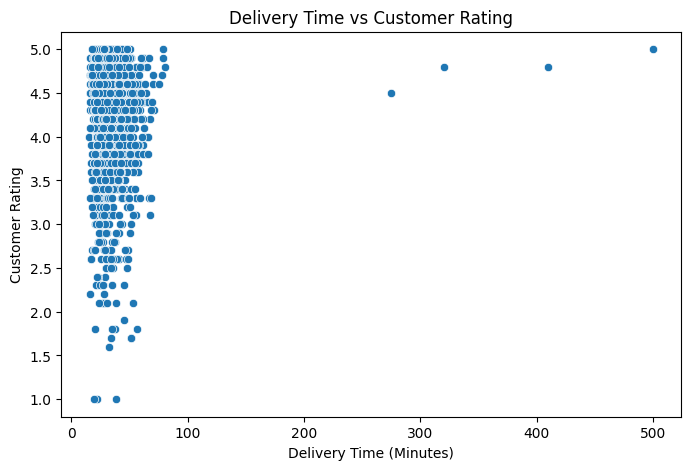

In [111]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x='delivery_time_min',
    y='customer_rating'
)

plt.title('Delivery Time vs Customer Rating')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Customer Rating')

plt.show()

Box Plot

Annual Spend by Membership

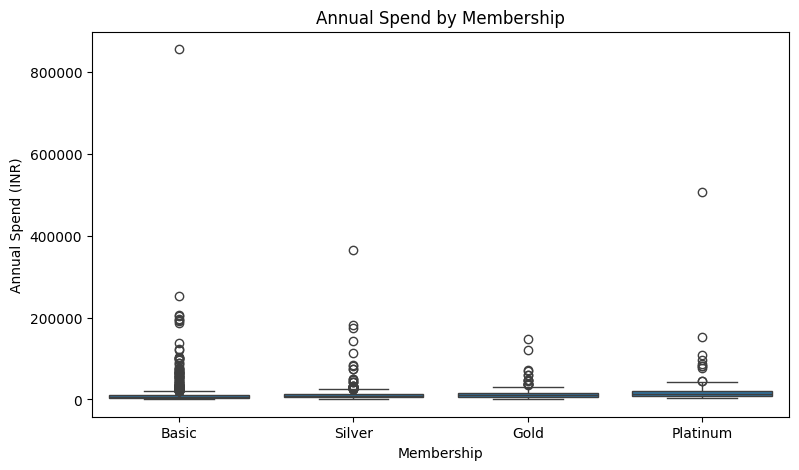

In [112]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=data,
    x='membership',
    y='annual_spend',
    order=['Basic', 'Silver', 'Gold', 'Platinum']
)

plt.title('Annual Spend by Membership')
plt.xlabel('Membership')
plt.ylabel('Annual Spend (INR)')

plt.show()

Delivery Time by City Tier

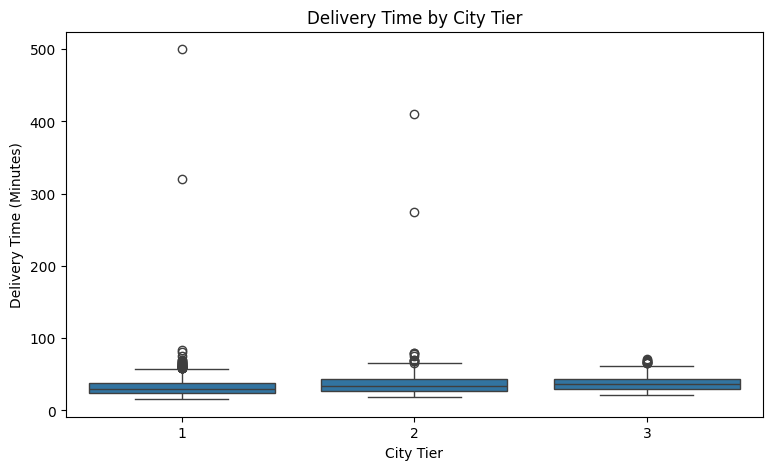

In [113]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=data,
    x='city_tier',
    y='delivery_time_min'
)

plt.title('Delivery Time by City Tier')
plt.xlabel('City Tier')
plt.ylabel('Delivery Time (Minutes)')

plt.show()

In [114]:
annual_corr = corr_matrix['annual_spend'].drop(
    'annual_spend'
)

print(annual_corr.sort_values(ascending=False))

orders_last_12m           0.724713
app_sessions_per_month    0.084869
avg_order_value           0.048745
age                       0.023505
customer_rating           0.001197
city_tier                -0.004363
tenure_months            -0.012000
delivery_time_min        -0.013485
days_since_last_order    -0.016463
discount_used_pct        -0.029959
Name: annual_spend, dtype: float64


# Task 5 Encoding

In [115]:
from sklearn.preprocessing import LabelEncoder

In [116]:
le = LabelEncoder()

data['membership_encoded'] = le.fit_transform(
    data['membership']
)

In [117]:
pip install category_encoders

In [118]:
from category_encoders import TargetEncoder

In [119]:
te = TargetEncoder()

In [120]:
data['city_encoded'] = te.fit_transform(
    data['city'],
    data['annual_spend']
)

In [121]:
data[['city', 'annual_spend', 'city_encoded']].head(10)

,city,annual_spend,city_encoded
0,Lucknow,8675.0,13939.896042
1,Bengaluru,7896.0,12004.006803
2,Indore,1826.0,10732.653164
3,Jaipur,90202.0,10410.655124
4,Mumbai,2773.0,12020.796875
5,Kochi,2604.0,15739.003760
6,Lucknow,9594.0,13939.896042
7,Lucknow,6532.0,13939.896042
8,Mumbai,3207.0,12020.796875
9,Bengaluru,2895.0,12004.006803


In [122]:
print("Age Mean: ", data.age.mean())
print("Age Median: ", data.age.median())
print("Age Mode: ", data.age.mode()[0])

print()

print("Orders_last_12m Mean: ", data.orders_last_12m.mean())
print("Orders_last_12m Median: ", data.orders_last_12m.median())
print("Orders_last_12m Mode: ", data.orders_last_12m.mode()[0])

print()

print("Annual_spend Mean: ", data.annual_spend.mean())
print("Annual_spend Median: ", data.annual_spend.median())
print("Annual_spend Mode: ", data.annual_spend.mode()[0])

print()

print("Membership Mode: ", data['membership'].mode()[0])

Age Mean:  31.9263836646964
Age Median:  32.0
Age Mode:  31.0

Orders_last_12m Mean:  34.8965
Orders_last_12m Median:  24.0
Orders_last_12m Mode:  17

Annual_spend Mean:  12995.852
Annual_spend Median:  7142.0
Annual_spend Mode:  2916.0

Membership Mode:  Basic


In [123]:
print("Annual Spend Mean: ", data.annual_spend.mean())
print("Annual Spend Median: ", data.annual_spend.median())

Annual Spend Mean:  12995.852
Annual Spend Median:  7142.0


In [124]:
print("P10: ", data.delivery_time_min.quantile(0.10))
print("P25: ", data.delivery_time_min.quantile(0.25))
print("P50: ", data.delivery_time_min.quantile(0.50))
print("P75: ", data.delivery_time_min.quantile(0.75))
print("P90: ", data.delivery_time_min.quantile(0.90))
print("P95: ", data.delivery_time_min.quantile(0.95))
print("P99: ", data.delivery_time_min.quantile(0.99))

P10:  22.0
P25:  26.2
P50:  32.25
P75:  40.5
P90:  49.51000000000001
P95:  56.0
P99:  68.76199999999999


Pareto Distribution

In [125]:
data_sorted = data.sort_values(
    by='annual_spend',
    ascending=False
)

data_sorted.head(10)

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend,membership_encoded,city_encoded
236,QB100236,2025-09-09,Hyderabad,1,Female,Android,Paid Social,36.0,13.9,15,29.8,NaN,4.6,16.9,1.0,Basic,400,855443.0,0,18300.340248
319,QB100319,2023-02-14,Nagpur,3,NaN,Android,Paid Social,31.0,45.2,19,39.0,993.0,4.4,23.8,3.0,Platinum,400,507406.0,2,15514.991220
687,QB100687,2023-10-27,Kochi,3,Female,Android,Referral,29.0,36.7,17,NaN,1024.0,3.3,6.1,44.0,Silver,334,364740.0,3,15739.003760
1686,QB101686,2025-02-27,Hyderabad,1,Male,Web,Search Ads,23.0,20.4,8,31.4,715.0,4.3,22.5,1.0,Basic,397,251922.0,0,18300.340248
1830,QB101830,2023-12-10,Hyderabad,1,Female,Android,Organic,28.0,35.2,16,34.0,666.0,4.2,31.9,43.0,Basic,370,207118.0,0,18300.340248
1162,QB101162,2023-10-26,Lucknow,2,Female,Android,Organic,38.0,36.7,16,59.0,590.0,4.8,13.3,22.0,Basic,370,203782.0,0,13939.896042
198,QB100198,2025-09-17,Delhi,1,Male,iOS,Referral,25.0,13.6,12,18.4,540.0,3.1,18.8,14.0,Basic,400,195694.0,0,12152.446667
1167,QB101167,2023-07-22,Hyderabad,1,Male,Android,Influencer,49.0,39.9,11,52.2,1099.0,NaN,32.0,2.0,Basic,210,193862.0,0,18300.340248
1924,QB101924,2025-08-05,Delhi,1,NaN,Android,Paid Social,36.0,15.1,13,40.6,557.0,NaN,27.9,32.0,Basic,400,191718.0,0,12152.446667
371,QB100371,2023-06-26,Delhi,1,Male,Web,Search Ads,40.0,40.8,12,46.7,533.0,4.6,25.6,5.0,Basic,400,185908.0,0,12152.446667


In [126]:
total_revenue = data_sorted['annual_spend'].sum()

print("Total Revenue:", total_revenue)

Total Revenue: 25991704.0


In [127]:
data_sorted['cumulative_revenue_share'] = (
    data_sorted['cumulative_revenue'] / total_revenue
) * 100

In [128]:
data_sorted[['annual_spend',
             'cumulative_revenue',
             'cumulative_revenue_share']].head(10)

,annual_spend,cumulative_revenue,cumulative_revenue_share
236,855443.0,855443.0,3.291216
319,507406.0,1362849.0,5.243400
687,364740.0,1727589.0,6.646694
1686,251922.0,1979511.0,7.615934
1830,207118.0,2186629.0,8.412796
1162,203782.0,2390411.0,9.196823
198,195694.0,2586105.0,9.949732
1167,193862.0,2779967.0,10.695593
1924,191718.0,2971685.0,11.433206
371,185908.0,3157593.0,12.148465


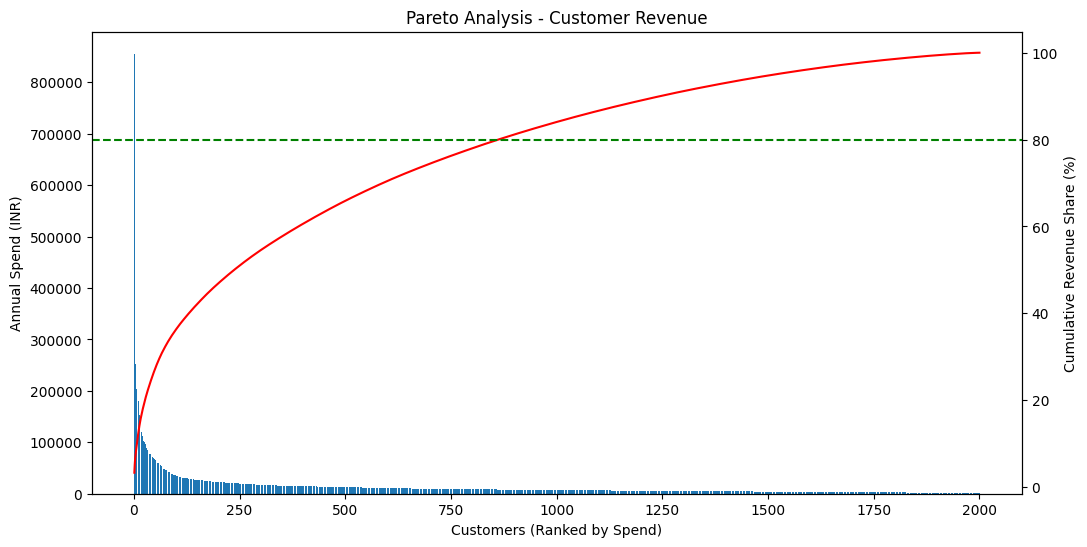

In [129]:
fig, ax1 = plt.subplots(figsize=(12,6))

ax1.bar(
    range(1, len(data_sorted)+1),
    data_sorted['annual_spend']
)

ax1.set_xlabel('Customers (Ranked by Spend)')
ax1.set_ylabel('Annual Spend (INR)')

ax2 = ax1.twinx()

ax2.plot(
    range(1, len(data_sorted)+1),
    data_sorted['cumulative_revenue_share'],
    color='red'
)

ax2.set_ylabel('Cumulative Revenue Share (%)')

ax2.axhline(80, linestyle='--', color='green')

plt.title('Pareto Analysis - Customer Revenue')

plt.show()

In [130]:
customers_50 = (
    data_sorted['cumulative_revenue_share'] >= 50
).idxmax()

print("Customers contributing 50% revenue:",
      data_sorted.index.get_loc(customers_50) + 1)

Customers contributing 50% revenue: 238


In [131]:
customers_80 = (
    data_sorted['cumulative_revenue_share'] >= 80
).idxmax()

print("Customers contributing 80% revenue:",
      data_sorted.index.get_loc(customers_80) + 1)

Customers contributing 80% revenue: 862


In [132]:
print("Total Customers:", len(data_sorted))

print("Percentage for 50% Revenue:",
      ((data_sorted.index.get_loc(customers_50)+1)
       / len(data_sorted))*100)

print("Percentage for 80% Revenue:",
      ((data_sorted.index.get_loc(customers_80)+1)
       / len(data_sorted))*100)

Total Customers: 2000
Percentage for 50% Revenue: 11.899999999999999
Percentage for 80% Revenue: 43.1


In [133]:
top_20 = int(len(data_sorted) * 0.20)

top_20_revenue = data_sorted.head(top_20)['annual_spend'].sum()

top_20_percentage = (
    top_20_revenue / total_revenue
) * 100

print("Top 20% Customers Revenue Share:",
      top_20_percentage)

Top 20% Customers Revenue Share: 60.61377122484928


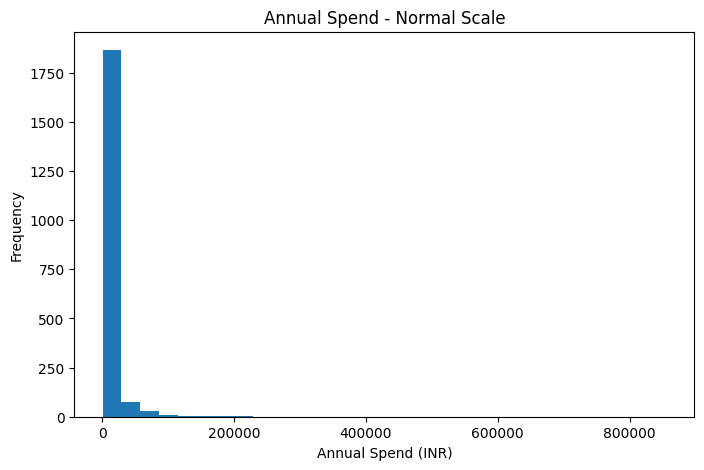

In [134]:
plt.figure(figsize=(8,5))

plt.hist(data['annual_spend'], bins=30)

plt.title('Annual Spend - Normal Scale')
plt.xlabel('Annual Spend (INR)')
plt.ylabel('Frequency')

plt.show()

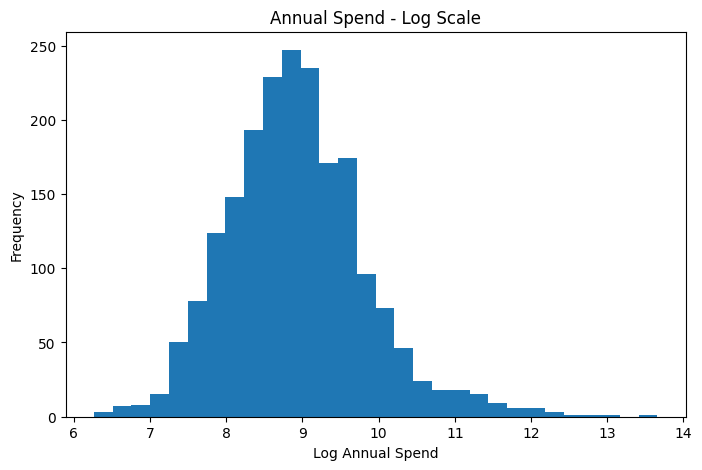

In [135]:
plt.figure(figsize=(8,5))

plt.hist(np.log1p(data['annual_spend']), bins=30)

plt.title('Annual Spend - Log Scale')
plt.xlabel('Log Annual Spend')
plt.ylabel('Frequency')

plt.show()

# Task 8 PDF and CDF

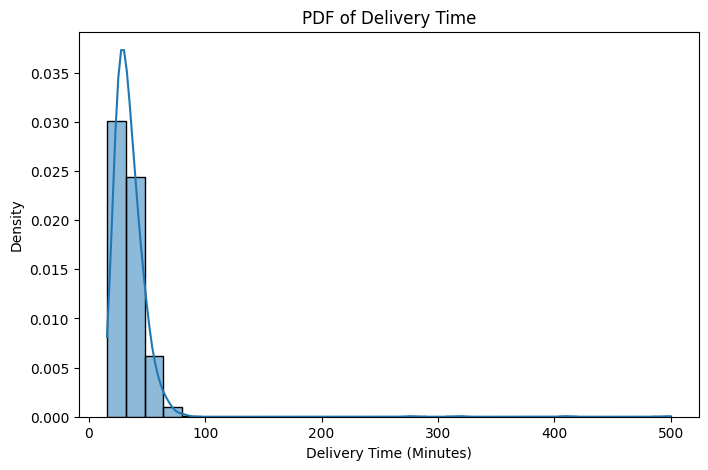

In [136]:
plt.figure(figsize=(8,5))

sns.histplot(data['delivery_time_min'], bins=30, stat='density', kde=True)

plt.title('PDF of Delivery Time')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Density')

plt.show()

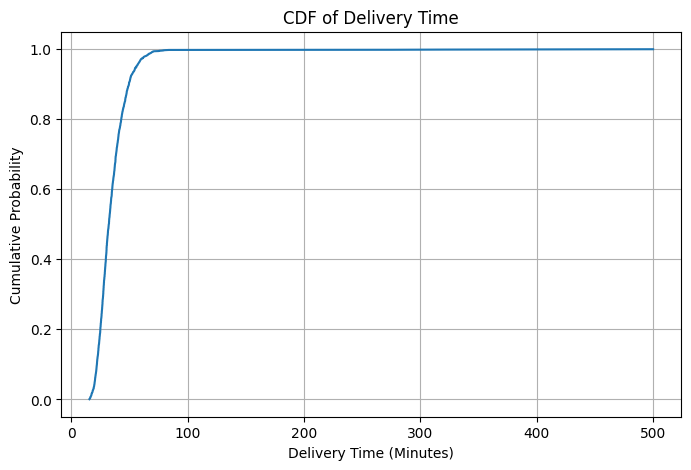

In [137]:
delivery_sorted = np.sort(data['delivery_time_min'].dropna())

delivery_cdf = np.arange(1, len(delivery_sorted) + 1) / len(delivery_sorted)

plt.figure(figsize=(8,5))

plt.plot(delivery_sorted, delivery_cdf)

plt.title('CDF of Delivery Time')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Cumulative Probability')

plt.grid()
plt.show()

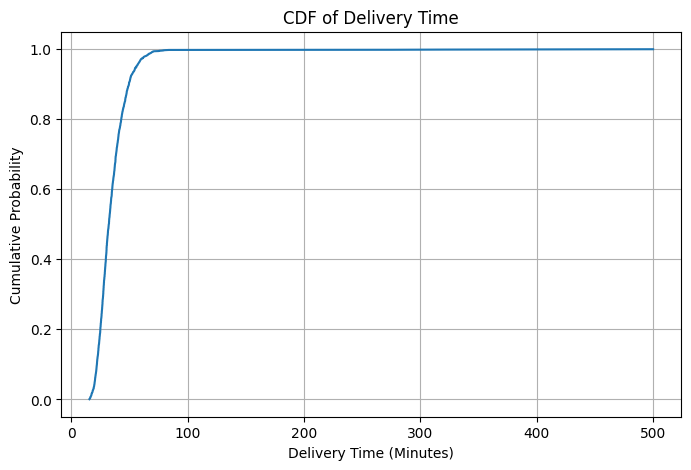

In [138]:
delivery_sorted = np.sort(data['delivery_time_min'].dropna())

delivery_cdf = np.arange(1, len(delivery_sorted) + 1) / len(delivery_sorted)

plt.figure(figsize=(8,5))

plt.plot(delivery_sorted, delivery_cdf)

plt.title('CDF of Delivery Time')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Cumulative Probability')

plt.grid()
plt.show()

In [139]:
prob_30 = (data['delivery_time_min'] <= 30).mean()

prob_45 = (data['delivery_time_min'] > 45).mean()

median_delivery = data['delivery_time_min'].median()

p95_delivery = data['delivery_time_min'].quantile(0.95)

print("Probability of delivery within 30 minutes:", prob_30)
print("Probability of delivery taking more than 45 minutes:", prob_45)
print("Median Delivery Time:", median_delivery)
print("95th Percentile Delivery Time:", p95_delivery)

Probability of delivery within 30 minutes: 0.3985
Probability of delivery taking more than 45 minutes: 0.158
Median Delivery Time: 32.25
95th Percentile Delivery Time: 56.0


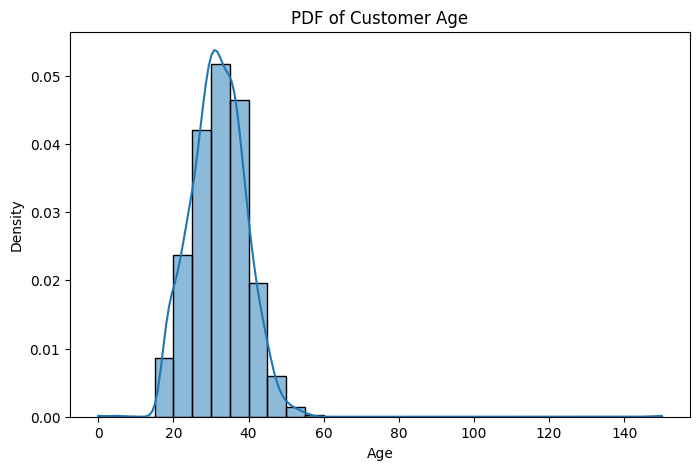

In [140]:
plt.figure(figsize=(8,5))

sns.histplot(data['age'], bins=30, stat='density', kde=True)

plt.title('PDF of Customer Age')
plt.xlabel('Age')
plt.ylabel('Density')

plt.show()

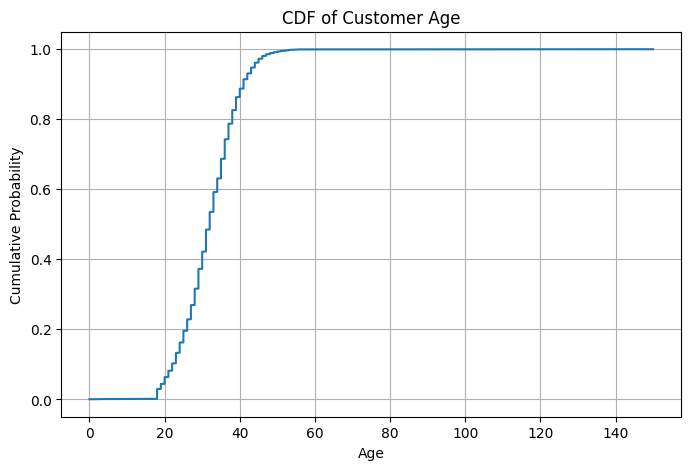

In [141]:
age_sorted = np.sort(data['age'].dropna())

age_cdf = np.arange(1, len(age_sorted) + 1) / len(age_sorted)

plt.figure(figsize=(8,5))

plt.plot(age_sorted, age_cdf)

plt.title('CDF of Customer Age')
plt.xlabel('Age')
plt.ylabel('Cumulative Probability')

plt.grid()
plt.show()

# Summary

Project Overview

The objective of this analysis was to understand customer spending patterns, identify valuable customer segments, evaluate delivery performance, and improve the reliability of QuickBite's customer data. The analysis was performed on a dataset of 2,000 customer records.

5 Key Insights

1. Customer data quality needed improvement

The dataset contains missing values and incorrect entries, including wrong customer ages and high delivery times and order values.

2. A small group of customers contributes a large share of revenue

Revenue is concentrated among high-spending customers. The top 20% of customers contribute approximately 60% of total revenue, showing that frequent and high-value customers are important to business growth.

3. Order frequency is associated with customer spending

The number of orders placed in the last 12 months has the strongest positive relationship with annual spending.

4. Higher membership are associated with higher spending

Median annual spending increases across membership levels, from approximately ₹5,875 for Basic members to ₹12,362.50 for Platinum members. This indicates that higher-tier members are valuable customer segments.

5. Delivery delays remain an area of concern

Only 39.85% of deliveries are completed within 30 minutes, while 15.8% take more than 45 minutes. The median delivery time is 32.25 minutes, and 95% of deliveries are completed within 56 minutes.

2 Business Recommendations

1. Focus on customer retention and loyalty

Introduce targeted loyalty rewards, personalised offers, and membership benefits to encourage repeat orders. Give special attention to frequent customers and high-spending customer.

2. Improve delivery performance

Investigate the reasons behind deliveries taking more than 45 minutes. Monitor delivery performance across cities and city tiers, identify operational bottlenecks, and work towards reducing delivery times to improve customer experience.